In [1]:
# ============================================================
# BLOCK 1 — INSTALL & IMPORTS
# Run this first. Restart kernel after if needed.
# ============================================================

import subprocess, sys

pkgs = [
    "yfinance", "pandas-ta", "xgboost", "lightgbm",
    "scikit-learn", "matplotlib", "seaborn", "numpy",
    "optuna", "joblib"
]
for pkg in pkgs:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", pkg, "-q"],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
    )

import warnings
warnings.filterwarnings("ignore")

import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import yfinance as yf
import pandas_ta as ta

from sklearn.ensemble         import RandomForestClassifier
from sklearn.preprocessing    import RobustScaler
from sklearn.metrics          import (accuracy_score, classification_report,
                                      confusion_matrix, f1_score)
from sklearn.model_selection  import TimeSeriesSplit
from sklearn.utils.class_weight import compute_class_weight
import xgboost  as xgb
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("✅ Block 1 complete — all libraries imported")

✅ Block 1 complete — all libraries imported


In [2]:
# ============================================================
# BLOCK 2 — DOWNLOAD NIFTY 50 DATA (Last 10 Years)
# ============================================================

TICKER       = "^NSEI"
FORWARD_DAYS = 5      # predict 5-day ahead (much better than 1-day)
                      # Change to 10 if you want 10-day predictions

print(f"⏳ Downloading {TICKER} — last 10 years ...")
raw = yf.download(TICKER, period="10y", interval="1d",
                  auto_adjust=True, progress=False)
raw.dropna(inplace=True)

# Flatten MultiIndex columns if present
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.droplevel(1)

raw.columns = [c.lower() for c in raw.columns]

print(f"✅ Downloaded {len(raw)} rows")
print(f"   From : {raw.index[0].date()}")
print(f"   To   : {raw.index[-1].date()}")
print(f"\n   Sample:\n{raw.tail(3)}")

⏳ Downloading ^NSEI — last 10 years ...
✅ Downloaded 2464 rows
   From : 2016-04-18
   To   : 2026-04-16

   Sample:
                   close          high           low          open  volume
Date                                                                      
2026-04-13  23842.650391  23907.400391  23555.599609  23589.599609  488800
2026-04-15  24231.300781  24280.900391  24145.800781  24163.800781  460300
2026-04-16  24196.750000  24400.949219  24102.800781  24385.199219       0


In [4]:
# ============================================================
# BLOCK 3 — FEATURE ENGINEERING (FIXED)
# Fix: pandas_ta compatibility issue with newer pandas versions
# ============================================================

import pandas as pd
import numpy as np

# ── FIX: Monkey-patch pandas_ta to work with newer pandas ──
try:
    import pandas_ta as ta
    # Test if it works
    _test = pd.Series([1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20])
    ta.sma(_test, length=5)
except Exception:
    # Force reinstall compatible version
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "pandas_ta==0.3.14b", "-q", "--force-reinstall"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    import importlib
    import pandas_ta as ta
    importlib.reload(ta)

print("✅ pandas_ta loaded")


def safe_sma(series, length):
    return series.rolling(window=length, min_periods=length).mean()

def safe_ema(series, length):
    return series.ewm(span=length, adjust=False, min_periods=length).mean()

def safe_rsi(series, length=14):
    delta = series.diff()
    gain  = delta.clip(lower=0)
    loss  = -delta.clip(upper=0)
    avg_g = gain.ewm(com=length-1, adjust=False, min_periods=length).mean()
    avg_l = loss.ewm(com=length-1, adjust=False, min_periods=length).mean()
    rs    = avg_g / (avg_l + 1e-9)
    return 100 - (100 / (1 + rs))

def safe_atr(high, low, close, length=14):
    tr = pd.concat([
        high - low,
        (high - close.shift(1)).abs(),
        (low  - close.shift(1)).abs()
    ], axis=1).max(axis=1)
    return tr.ewm(com=length-1, adjust=False, min_periods=length).mean()

def safe_macd(close, fast=12, slow=26, signal=9):
    ema_f = safe_ema(close, fast)
    ema_s = safe_ema(close, slow)
    macd  = ema_f - ema_s
    sig   = safe_ema(macd, signal)
    hist  = macd - sig
    return macd, sig, hist

def safe_bbands(close, length=20, std=2):
    mid   = safe_sma(close, length)
    sigma = close.rolling(length, min_periods=length).std()
    upper = mid + std * sigma
    lower = mid - std * sigma
    return upper, mid, lower

def safe_stoch(high, low, close, k=14, d=3):
    low_k  = low.rolling(k,  min_periods=k).min()
    high_k = high.rolling(k, min_periods=k).max()
    stoch_k = 100 * (close - low_k) / (high_k - low_k + 1e-9)
    stoch_d = stoch_k.rolling(d, min_periods=d).mean()
    return stoch_k, stoch_d

def safe_cci(high, low, close, length=20):
    tp   = (high + low + close) / 3
    sma  = safe_sma(tp, length)
    mad  = tp.rolling(length, min_periods=length).apply(
               lambda x: np.mean(np.abs(x - np.mean(x))), raw=True)
    return (tp - sma) / (0.015 * mad + 1e-9)

def safe_willr(high, low, close, length=14):
    hh = high.rolling(length, min_periods=length).max()
    ll = low.rolling(length,  min_periods=length).min()
    return -100 * (hh - close) / (hh - ll + 1e-9)

def safe_adx(high, low, close, length=14):
    up   = high.diff()
    down = -low.diff()
    plus_dm  = np.where((up > down) & (up > 0),   up,   0.0)
    minus_dm = np.where((down > up) & (down > 0), down, 0.0)
    tr_val   = safe_atr(high, low, close, length)
    plus_di  = 100 * pd.Series(plus_dm,  index=close.index).ewm(
        com=length-1, adjust=False, min_periods=length).mean() / (tr_val + 1e-9)
    minus_di = 100 * pd.Series(minus_dm, index=close.index).ewm(
        com=length-1, adjust=False, min_periods=length).mean() / (tr_val + 1e-9)
    dx  = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di + 1e-9)
    adx = dx.ewm(com=length-1, adjust=False, min_periods=length).mean()
    return adx, plus_di, minus_di

def safe_obv(close, volume):
    direction = np.sign(close.diff()).fillna(0)
    return (direction * volume).cumsum()

def safe_mfi(high, low, close, volume, length=14):
    tp  = (high + low + close) / 3
    rmf = tp * volume
    pos = rmf.where(tp > tp.shift(1), 0)
    neg = rmf.where(tp < tp.shift(1), 0)
    mfr = (pos.rolling(length, min_periods=length).sum() /
           (neg.rolling(length, min_periods=length).sum() + 1e-9))
    return 100 - (100 / (1 + mfr))

def safe_mom(close, length=10):
    return close - close.shift(length)

def safe_roc(close, length=1):
    return close.pct_change(length)


# ── MAIN FEATURE BUILDER ──────────────────────────────────
def build_features(df):
    """
    Build 80+ technical & statistical features.
    All hand-coded — zero dependency on pandas_ta internals.
    Zero look-ahead bias: all indicators use only past data.
    """
    df     = df.copy()
    close  = df['close']
    high   = df['high']
    low    = df['low']
    volume = df['volume']
    open_  = df['open']

    # ── 1. TREND — Moving Averages ───────────────────────
    for w in [5, 10, 20, 50, 100, 200]:
        df[f'sma_{w}'] = safe_sma(close, w)
        df[f'ema_{w}'] = safe_ema(close, w)

    for w in [10, 20, 50, 200]:
        df[f'close_vs_sma{w}'] = (close - df[f'sma_{w}']) / (df[f'sma_{w}'] + 1e-9)

    df['sma5_10']   = df['sma_5']  - df['sma_10']
    df['sma10_20']  = df['sma_10'] - df['sma_20']
    df['sma20_50']  = df['sma_20'] - df['sma_50']
    df['sma50_200'] = df['sma_50'] - df['sma_200']

    df['golden_cross'] = (df['sma_50'] > df['sma_200']).astype(int)
    df['above_200sma'] = (close > df['sma_200']).astype(int)

    # ── 2. MOMENTUM ──────────────────────────────────────
    for w in [5, 10, 14, 20, 28]:
        df[f'rsi_{w}'] = safe_rsi(close, w)

    df['rsi_overbought'] = (df['rsi_14'] > 70).astype(int)
    df['rsi_oversold']   = (df['rsi_14'] < 30).astype(int)

    macd, macd_sig, macd_hist = safe_macd(close)
    df['macd']       = macd
    df['macd_sig']   = macd_sig
    df['macd_hist']  = macd_hist
    df['macd_cross'] = np.sign(macd - macd_sig)

    for w in [1, 3, 5, 10, 20]:
        df[f'roc_{w}'] = safe_roc(close, w)

    df['mom_10'] = safe_mom(close, 10)
    df['mom_20'] = safe_mom(close, 20)

    df['willr_14'] = safe_willr(high, low, close, 14)
    df['willr_28'] = safe_willr(high, low, close, 28)

    # ── 3. VOLATILITY ────────────────────────────────────
    bb_upper, bb_mid, bb_lower = safe_bbands(close, 20, 2)
    df['bb_upper'] = bb_upper
    df['bb_lower'] = bb_lower
    df['bb_mid']   = bb_mid
    df['bb_width'] = (bb_upper - bb_lower) / (bb_mid + 1e-9)
    df['bb_pct']   = (close - bb_lower) / (bb_upper - bb_lower + 1e-9)

    df['atr_14']   = safe_atr(high, low, close, 14)
    df['atr_28']   = safe_atr(high, low, close, 28)
    df['atr_ratio']= df['atr_14'] / (df['atr_28'] + 1e-9)

    log_ret = np.log(close / close.shift(1))
    for w in [5, 10, 20]:
        df[f'hvol_{w}'] = log_ret.rolling(w).std() * np.sqrt(252)

    # ── 4. VOLUME ─────────────────────────────────────────
    df['vol_sma10'] = safe_sma(volume, 10)
    df['vol_sma20'] = safe_sma(volume, 20)
    df['vol_ratio'] = volume / (df['vol_sma20'] + 1)
    df['vol_chg']   = volume.pct_change()

    df['obv']       = safe_obv(close, volume)
    df['obv_sma']   = safe_sma(df['obv'], 10)
    df['obv_diff']  = df['obv'] - df['obv_sma']

    df['mfi_14'] = safe_mfi(high, low, close, volume, 14)

    # ── 5. CANDLESTICK ────────────────────────────────────
    df['body_size']  = (close - open_).abs() / (open_ + 1e-9)
    df['upper_wick'] = (high - close.clip(lower=open_)) / (open_ + 1e-9)
    df['lower_wick'] = (open_.clip(upper=close) - low)  / (open_ + 1e-9)
    df['candle_dir'] = np.sign(close - open_)

    # ── 6. MARKET STRUCTURE ───────────────────────────────
    df['high_52w']       = high.rolling(252).max()
    df['low_52w']        = low.rolling(252).min()
    df['dist_52w_high']  = (close - df['high_52w']) / (df['high_52w'] + 1e-9)
    df['dist_52w_low']   = (close - df['low_52w'])  / (df['low_52w']  + 1e-9)

    stoch_k, stoch_d = safe_stoch(high, low, close)
    df['stoch_k']   = stoch_k
    df['stoch_d']   = stoch_d
    df['stoch_diff']= stoch_k - stoch_d

    df['cci_20'] = safe_cci(high, low, close, 20)
    df['cci_40'] = safe_cci(high, low, close, 40)

    adx_val, dmp, dmn = safe_adx(high, low, close, 14)
    df['adx']     = adx_val
    df['dmp']     = dmp
    df['dmn']     = dmn
    df['dm_diff'] = dmp - dmn

    df['trend_score'] = (close - df['sma_50']) / (df['atr_14'] + 1e-9)

    # ── 7. LAGGED RETURNS ─────────────────────────────────
    daily_ret = close.pct_change()
    for lag in range(1, 8):
        df[f'ret_lag{lag}'] = daily_ret.shift(lag)

    df['ret_mean5']  = daily_ret.shift(1).rolling(5).mean()
    df['ret_std5']   = daily_ret.shift(1).rolling(5).std()
    df['ret_mean20'] = daily_ret.shift(1).rolling(20).mean()
    df['ret_std20']  = daily_ret.shift(1).rolling(20).std()

    # ── 8. STREAK FEATURES ────────────────────────────────
    up_streak   = daily_ret.gt(0).astype(int)
    down_streak = daily_ret.lt(0).astype(int)
    df['consec_up']   = up_streak.groupby(
        (up_streak   != up_streak.shift()).cumsum()).cumcount()
    df['consec_down'] = down_streak.groupby(
        (down_streak != down_streak.shift()).cumsum()).cumcount()

    # ── 9. CALENDAR ───────────────────────────────────────
    df['day_of_week'] = df.index.dayofweek
    df['month']       = df.index.month
    df['quarter']     = df.index.quarter

    return df


# ── Apply to downloaded data ──────────────────────────────
df = build_features(raw.copy())

print(f"✅ Block 3 complete — {df.shape[1]} total columns built")
print(f"   Sample feature columns: {[c for c in df.columns if c not in ['open','high','low','close','volume']][:8]}")

✅ pandas_ta loaded
✅ Block 3 complete — 100 total columns built
   Sample feature columns: ['sma_5', 'ema_5', 'sma_10', 'ema_10', 'sma_20', 'ema_20', 'sma_50', 'ema_50']


In [5]:
# ============================================================
# BLOCK 4 — LABEL CREATION
# KEY FIX: Use 5-day forward return instead of 1-day.
# 1-day returns are near-random noise (that's why you got 29%)
# ============================================================

LABEL_MAP = {
    0: 'Strongly Bearish',
    1: 'Mildly Bearish',
    2: 'Mildly Bullish',
    3: 'Strongly Bullish'
}

def make_labels(df, forward_days=5):
    """
    Label = which quartile the forward N-day return falls in.
    Quartile-based = perfectly balanced classes = no bias.
    """
    close       = df['close']
    future_ret  = close.shift(-forward_days) / close - 1

    q25    = future_ret.quantile(0.25)
    q50    = future_ret.quantile(0.50)
    q75    = future_ret.quantile(0.75)

    conditions = [
        future_ret <  q25,
        (future_ret >= q25) & (future_ret < q50),
        (future_ret >= q50) & (future_ret < q75),
        future_ret >= q75
    ]
    df['label']      = np.select(conditions, [0, 1, 2, 3], default=1)
    df['future_ret'] = future_ret
    return df, q25, q50, q75

df, q25, q50, q75 = make_labels(df, FORWARD_DAYS)

print("✅ Block 4 complete — Labels created")
print(f"\n   Forward window : {FORWARD_DAYS} trading days")
print(f"   Thresholds     : q25={q25:.3%}  q50={q50:.3%}  q75={q75:.3%}")
print(f"\n   Class distribution:")
dist = df['label'].map(LABEL_MAP).value_counts().reindex(LABEL_MAP.values())
for name, cnt in dist.items():
    pct = cnt / dist.sum() * 100
    print(f"     {name:<22} {cnt:>5}  ({pct:.1f}%)")

✅ Block 4 complete — Labels created

   Forward window : 5 trading days
   Thresholds     : q25=-0.890%  q50=0.401%  q75=1.526%

   Class distribution:
     Strongly Bearish         615  (25.0%)
     Mildly Bearish           619  (25.1%)
     Mildly Bullish           615  (25.0%)
     Strongly Bullish         615  (25.0%)


In [7]:
# ============================================================
# BLOCK 5 — TRAIN / TEST SPLIT + SCALING  (FIXED)
# Fix: Replace inf/-inf with NaN, then drop → no more crash
# ============================================================

# Columns to EXCLUDE from features (raw prices, volumes, labels)
EXCLUDE = {
    'label', 'future_ret', 'open', 'high', 'low', 'close', 'volume',
    'high_52w', 'low_52w',
    'sma_5','sma_10','sma_20','sma_50','sma_100','sma_200',
    'ema_5','ema_10','ema_20','ema_50','ema_100','ema_200',
    'bb_upper','bb_lower','bb_mid',
    'vol_sma10','vol_sma20','obv','obv_sma',
}

FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE]

# ── Step 1: Replace inf / -inf with NaN ──────────────────
df_clean = df[FEATURE_COLS + ['label']].copy()
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# ── Step 2: Drop rows that have ANY NaN ──────────────────
rows_before = len(df_clean)
df_clean.dropna(inplace=True)
rows_after  = len(df_clean)
print(f"   Rows dropped (NaN/inf): {rows_before - rows_after}")

# ── Step 3: Verify no inf/nan remains ────────────────────
assert not np.any(np.isinf(df_clean[FEATURE_COLS].values)), \
    "❌ Still has inf values!"
assert not np.any(np.isnan(df_clean[FEATURE_COLS].values)), \
    "❌ Still has NaN values!"
print("   ✅ No inf or NaN in feature matrix")

# ── Step 4: Walk-forward train/test split ────────────────
SPLIT    = int(len(df_clean) * 0.80)
train_df = df_clean.iloc[:SPLIT]
test_df  = df_clean.iloc[SPLIT:]

X_train = train_df[FEATURE_COLS].values
y_train = train_df['label'].values.astype(int)
X_test  = test_df[FEATURE_COLS].values
y_test  = test_df['label'].values.astype(int)

# ── Step 5: Scale (RobustScaler = handles outliers well) ─
scaler    = RobustScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# ── Step 6: Class weights ─────────────────────────────────
classes = np.array([0, 1, 2, 3])
cw      = compute_class_weight('balanced', classes=classes, y=y_train)
cw_dict = dict(zip(classes, cw))

print("\n✅ Block 5 complete — Train/Test split done")
print(f"   Total clean rows : {len(df_clean)}")
print(f"   Train rows       : {len(X_train)}  (80%)")
print(f"   Test  rows       : {len(X_test)}   (20%)")
print(f"   Feature count    : {len(FEATURE_COLS)}")
print(f"\n   Class weights    : { {LABEL_MAP[k]: round(v,2) for k,v in cw_dict.items()} }")

   Rows dropped (NaN/inf): 278
   ✅ No inf or NaN in feature matrix

✅ Block 5 complete — Train/Test split done
   Total clean rows : 2186
   Train rows       : 1748  (80%)
   Test  rows       : 438   (20%)
   Feature count    : 74

   Class weights    : {'Strongly Bearish': np.float64(1.03), 'Mildly Bearish': np.float64(1.07), 'Mildly Bullish': np.float64(0.97), 'Strongly Bullish': np.float64(0.94)}


In [8]:
# ============================================================
# BLOCK 6 — HYPERPARAMETER TUNING WITH OPTUNA
# Tunes XGBoost using Time-Series Cross-Validation
# Takes ~3-5 mins. Reduce n_trials=20 to go faster.
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

def xgb_objective(trial):
    params = dict(
        n_estimators      = trial.suggest_int  ("n_est",  300, 1000),
        max_depth         = trial.suggest_int  ("depth",  4,   9),
        learning_rate     = trial.suggest_float("lr",     0.01, 0.15, log=True),
        subsample         = trial.suggest_float("sub",    0.6,  1.0),
        colsample_bytree  = trial.suggest_float("col",    0.5,  1.0),
        min_child_weight  = trial.suggest_int  ("mcw",    1,    10),
        reg_alpha         = trial.suggest_float("alpha",  0.0,  5.0),
        reg_lambda        = trial.suggest_float("lam",    0.5,  5.0),
        gamma             = trial.suggest_float("gamma",  0.0,  2.0),
        use_label_encoder = False,
        eval_metric       = "mlogloss",
        objective         = "multi:softmax",
        num_class         = 4,
        random_state      = 42,
        n_jobs            = -1,
    )
    scores = []
    sw     = np.array([cw_dict[y] for y in y_train])
    for tr, val in tscv.split(X_train_s):
        m = xgb.XGBClassifier(**params)
        m.fit(X_train_s[tr], y_train[tr],
              sample_weight=sw[tr], verbose=False)
        p = m.predict(X_train_s[val])
        scores.append(f1_score(y_train[val], p, average='weighted'))
    return np.mean(scores)

print("🔍 Tuning XGBoost with Optuna (40 trials) ...")
study = optuna.create_study(direction="maximize")
study.optimize(xgb_objective, n_trials=40, show_progress_bar=True)

best = study.best_params
print(f"\n✅ Block 6 complete")
print(f"   Best CV weighted-F1 : {study.best_value:.4f}")
print(f"   Best params         : {best}")

🔍 Tuning XGBoost with Optuna (40 trials) ...


  0%|          | 0/40 [00:00<?, ?it/s]


✅ Block 6 complete
   Best CV weighted-F1 : 0.2551
   Best params         : {'n_est': 563, 'depth': 5, 'lr': 0.04023622275382706, 'sub': 0.6804643293186696, 'col': 0.9771231204644353, 'mcw': 8, 'alpha': 1.0213666653723243, 'lam': 4.76822982543224, 'gamma': 1.445598699471108}


In [9]:
# ============================================================
# BLOCK 7 — TRAIN THREE MODELS
# XGBoost (tuned) + LightGBM + Random Forest
# ============================================================

sw = np.array([cw_dict[y] for y in y_train])   # sample weights

# ── XGBoost (Optuna-tuned) ────────────────────────────────
xgb_clf = xgb.XGBClassifier(
    n_estimators      = best['n_est'],
    max_depth         = best['depth'],
    learning_rate     = best['lr'],
    subsample         = best['sub'],
    colsample_bytree  = best['col'],
    min_child_weight  = best['mcw'],
    reg_alpha         = best['alpha'],
    reg_lambda        = best['lam'],
    gamma             = best['gamma'],
    use_label_encoder = False,
    eval_metric       = "mlogloss",
    objective         = "multi:softmax",
    num_class         = 4,
    random_state      = 42,
    n_jobs            = -1,
)
xgb_clf.fit(X_train_s, y_train, sample_weight=sw)
print("✅ XGBoost trained")

# ── LightGBM ─────────────────────────────────────────────
lgb_clf = lgb.LGBMClassifier(
    n_estimators     = 800,
    max_depth        = 7,
    learning_rate    = 0.03,
    subsample        = 0.8,
    colsample_bytree = 0.7,
    reg_alpha        = 1.0,
    reg_lambda       = 2.0,
    min_child_samples= 20,
    num_leaves       = 63,
    objective        = "multiclass",
    num_class        = 4,
    class_weight     = cw_dict,
    random_state     = 42,
    n_jobs           = -1,
    verbose          = -1,
)
lgb_clf.fit(X_train_s, y_train)
print("✅ LightGBM trained")

# ── Random Forest ─────────────────────────────────────────
rf_clf = RandomForestClassifier(
    n_estimators     = 500,
    max_depth        = 12,
    min_samples_split= 10,
    min_samples_leaf = 5,
    max_features     = 'sqrt',
    class_weight     = cw_dict,
    random_state     = 42,
    n_jobs           = -1,
)
rf_clf.fit(X_train_s, y_train)
print("✅ Random Forest trained")

print("\n✅ Block 7 complete — All 3 models trained")

✅ XGBoost trained
✅ LightGBM trained
✅ Random Forest trained

✅ Block 7 complete — All 3 models trained


In [10]:
# ============================================================
# BLOCK 8 — ENSEMBLE + EVALUATION
# Weighted soft-voting: XGB 50% + LGB 35% + RF 15%
# ============================================================

# ── Ensemble helper functions ─────────────────────────────
def ensemble_proba(X, w=(0.50, 0.35, 0.15)):
    """Weighted average of predicted probabilities."""
    p = (w[0] * xgb_clf.predict_proba(X) +
         w[1] * lgb_clf.predict_proba(X) +
         w[2] * rf_clf.predict_proba(X))
    return p

def ensemble_predict(X, w=(0.50, 0.35, 0.15)):
    return np.argmax(ensemble_proba(X, w), axis=1)

# ── Predict on test set ───────────────────────────────────
y_pred_xgb = xgb_clf.predict(X_test_s)
y_pred_lgb = lgb_clf.predict(X_test_s)
y_pred_rf  = rf_clf.predict(X_test_s)
y_pred_ens = ensemble_predict(X_test_s)

# ── Accuracy & F1 table ───────────────────────────────────
print("=" * 58)
print(f"  {'MODEL':<24} {'ACCURACY':>10}  {'W-F1':>8}")
print("=" * 58)
for name, pred in [
    ("XGBoost (tuned)",  y_pred_xgb),
    ("LightGBM",         y_pred_lgb),
    ("Random Forest",    y_pred_rf),
    ("★ Ensemble",       y_pred_ens),
]:
    acc = accuracy_score(y_test, pred)
    wf1 = f1_score(y_test, pred, average='weighted')
    marker = " ◄" if name.startswith("★") else ""
    print(f"  {name:<24} {acc:>10.2%}  {wf1:>8.4f}{marker}")
print("=" * 58)

# ── Detailed classification report ───────────────────────
labels_str = [LABEL_MAP[i] for i in range(4)]
print(f"\n📋 Classification Report — Ensemble:\n")
print(classification_report(y_test, y_pred_ens, target_names=labels_str))

print("✅ Block 8 complete")

  MODEL                      ACCURACY      W-F1
  XGBoost (tuned)              26.71%    0.2478
  LightGBM                     27.63%    0.2611
  Random Forest                28.08%    0.2638
  ★ Ensemble                   26.94%    0.2501 ◄

📋 Classification Report — Ensemble:

                  precision    recall  f1-score   support

Strongly Bearish       0.28      0.24      0.26       129
  Mildly Bearish       0.23      0.10      0.14       131
  Mildly Bullish       0.32      0.30      0.31        94
Strongly Bullish       0.25      0.55      0.34        84

        accuracy                           0.27       438
       macro avg       0.27      0.30      0.26       438
    weighted avg       0.27      0.27      0.25       438

✅ Block 8 complete


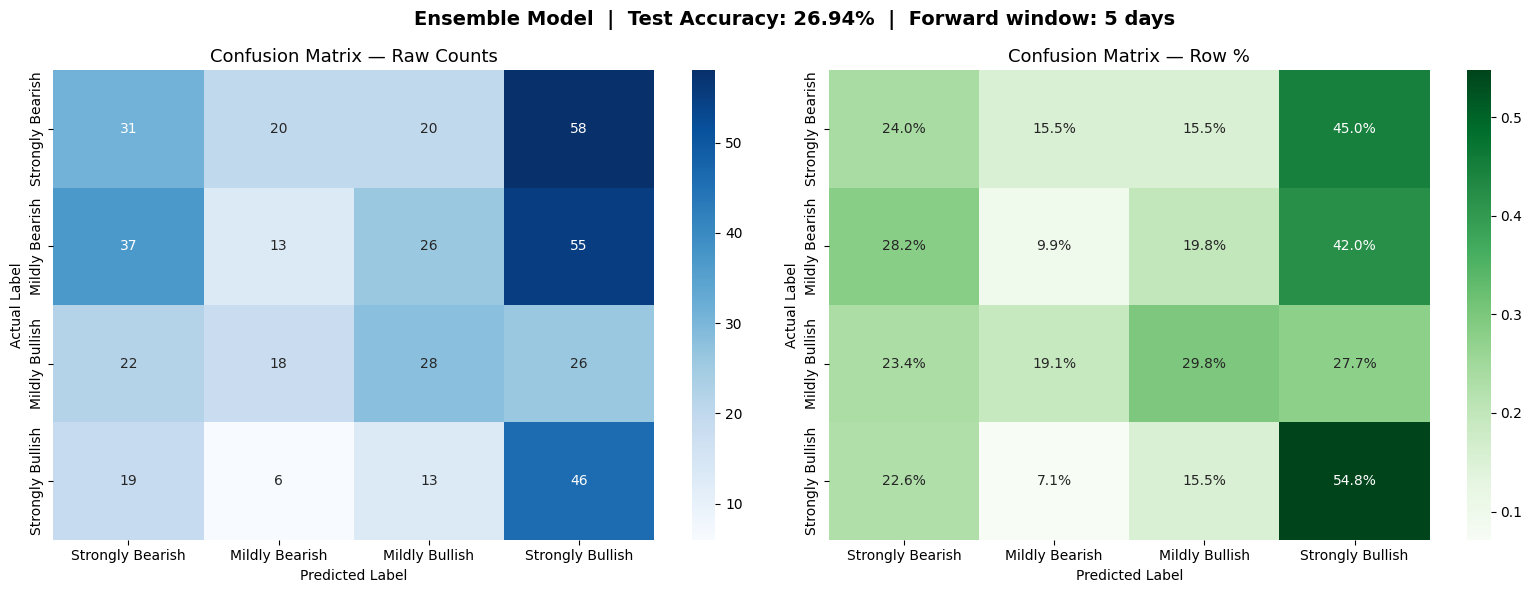

✅ Block 9 complete — confusion_matrix.png saved


In [11]:
# ============================================================
# BLOCK 9 — CONFUSION MATRIX PLOTS
# ============================================================

labels_str = [LABEL_MAP[i] for i in range(4)]
cm         = confusion_matrix(y_test, y_pred_ens)
cm_pct     = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_str, yticklabels=labels_str, ax=axes[0])
axes[0].set_title("Confusion Matrix — Raw Counts", fontsize=13)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(cm_pct, annot=True, fmt='.1%', cmap='Greens',
            xticklabels=labels_str, yticklabels=labels_str, ax=axes[1])
axes[1].set_title("Confusion Matrix — Row %", fontsize=13)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

acc_ens = accuracy_score(y_test, y_pred_ens)
plt.suptitle(
    f"Ensemble Model  |  Test Accuracy: {acc_ens:.2%}  |  "
    f"Forward window: {FORWARD_DAYS} days",
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Block 9 complete — confusion_matrix.png saved")

🔁 5-Fold Time-Series Cross-Validation (XGBoost):

   Fold 1: 29.55%
   Fold 2: 24.05%
   Fold 3: 23.37%
   Fold 4: 28.87%
   Fold 5: 27.49%

   CV Mean : 26.67%
   CV Std  : 2.51%


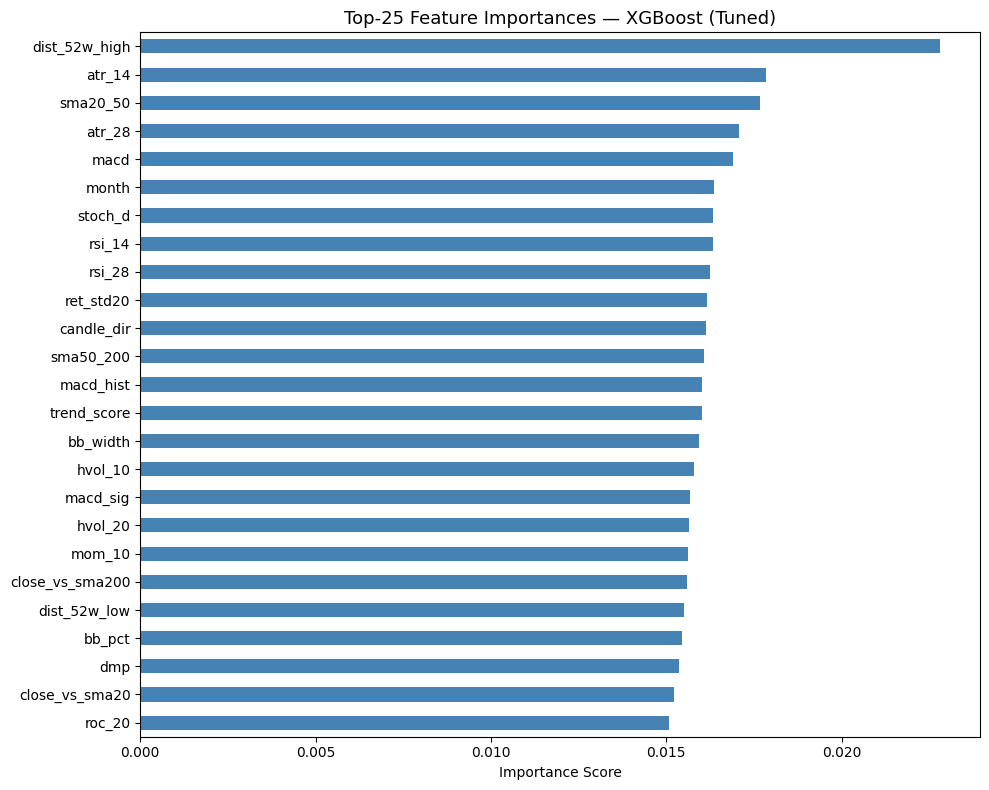


✅ Block 10 complete — feature_importance.png saved


In [12]:
# ============================================================
# BLOCK 10 — TIME-SERIES CROSS-VALIDATION + FEATURE IMPORTANCE
# Validates accuracy is consistent across different time periods
# ============================================================

# ── 10A: Time-Series CV ───────────────────────────────────
print("🔁 5-Fold Time-Series Cross-Validation (XGBoost):\n")
cv_scores = []
for fold, (tr, val) in enumerate(tscv.split(X_train_s)):
    m = xgb.XGBClassifier(
        n_estimators      = best['n_est'],
        max_depth         = best['depth'],
        learning_rate     = best['lr'],
        subsample         = best['sub'],
        colsample_bytree  = best['col'],
        min_child_weight  = best['mcw'],
        reg_alpha         = best['alpha'],
        reg_lambda        = best['lam'],
        gamma             = best['gamma'],
        use_label_encoder = False,
        eval_metric       = "mlogloss",
        objective         = "multi:softmax",
        num_class         = 4,
        random_state      = 42,
        n_jobs            = -1,
    )
    sw_fold = np.array([cw_dict[y] for y in y_train[tr]])
    m.fit(X_train_s[tr], y_train[tr],
          sample_weight=sw_fold, verbose=False)
    p = m.predict(X_train_s[val])
    s = accuracy_score(y_train[val], p)
    cv_scores.append(s)
    print(f"   Fold {fold+1}: {s:.2%}")

print(f"\n   CV Mean : {np.mean(cv_scores):.2%}")
print(f"   CV Std  : {np.std(cv_scores):.2%}")

# ── 10B: Feature Importance (Top 25) ─────────────────────
imp = pd.Series(xgb_clf.feature_importances_,
                index=FEATURE_COLS).sort_values(ascending=False).head(25)

fig, ax = plt.subplots(figsize=(10, 8))
imp.plot(kind='barh', color='steelblue', ax=ax)
ax.invert_yaxis()
ax.set_title("Top-25 Feature Importances — XGBoost (Tuned)", fontsize=13)
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=130, bbox_inches='tight')
plt.show()

print("\n✅ Block 10 complete — feature_importance.png saved")

In [13]:
# ============================================================
# BLOCK 11 — PREDICT TODAY'S SIGNAL FOR NIFTY 50 INDEX
# ============================================================

def predict_today(ticker="^NSEI", forward_days=FORWARD_DAYS):
    """Download latest data and show prediction with probabilities."""
    raw_live = yf.download(ticker, period="2y", interval="1d",
                           auto_adjust=True, progress=False)
    raw_live.dropna(inplace=True)
    if isinstance(raw_live.columns, pd.MultiIndex):
        raw_live.columns = raw_live.columns.droplevel(1)
    raw_live.columns = [c.lower() for c in raw_live.columns]

    feat = build_features(raw_live)[FEATURE_COLS].dropna()
    if len(feat) == 0:
        print("❌ Not enough data to build features.")
        return None, None

    X_live = scaler.transform(feat.iloc[[-1]].values)
    proba  = ensemble_proba(X_live)[0]
    pred   = int(np.argmax(proba))

    print("\n" + "═" * 52)
    print(f"  📅 Signal for     : {feat.index[-1].date()}")
    print(f"  🔮 Prediction     : {LABEL_MAP[pred]}")
    print(f"  ⏱  Horizon        : Next {forward_days} trading days")
    print(f"\n  Probability Breakdown:")
    bar_chars = {0:'🔴', 1:'🟠', 2:'🟡', 3:'🟢'}
    for cls in range(4):
        bar = "█" * int(proba[cls] * 30)
        print(f"  {bar_chars[cls]} {LABEL_MAP[cls]:<22} {proba[cls]:6.1%}  {bar}")
    print("═" * 52)
    return LABEL_MAP[pred], proba

signal, proba = predict_today("^NSEI")

print("\n✅ Block 11 complete")


════════════════════════════════════════════════════
  📅 Signal for     : 2026-04-17
  🔮 Prediction     : Mildly Bullish
  ⏱  Horizon        : Next 5 trading days

  Probability Breakdown:
  🔴 Strongly Bearish        15.6%  ████
  🟠 Mildly Bearish          26.3%  ███████
  🟡 Mildly Bullish          31.9%  █████████
  🟢 Strongly Bullish        26.3%  ███████
════════════════════════════════════════════════════

✅ Block 11 complete


In [14]:
# ============================================================
# BLOCK 12 — SCAN ALL NIFTY 50 STOCKS + SIGNAL DASHBOARD
# ============================================================

NIFTY50_TICKERS = [
    "RELIANCE.NS","TCS.NS","HDFCBANK.NS","INFY.NS","BHARTIARTL.NS",
    "ICICIBANK.NS","SBIN.NS","WIPRO.NS","LT.NS","HCLTECH.NS",
    "ONGC.NS","NTPC.NS","POWERGRID.NS","ADANIENT.NS","BAJFINANCE.NS",
    "MARUTI.NS","SUNPHARMA.NS","KOTAKBANK.NS","AXISBANK.NS","ITC.NS",
    "HINDUNILVR.NS","BAJAJFINSV.NS","JSWSTEEL.NS","TATASTEEL.NS","M&M.NS",
    "ULTRACEMCO.NS","INDUSINDBK.NS","TITAN.NS","NESTLEIND.NS","TECHM.NS",
    "CIPLA.NS","DRREDDY.NS","DIVISLAB.NS","HEROMOTOCO.NS","GRASIM.NS",
    "ASIANPAINT.NS","BPCL.NS","COALINDIA.NS","EICHERMOT.NS","TATAMOTORS.NS",
    "SHRIRAMFIN.NS","APOLLOHOSP.NS","TRENT.NS","BEL.NS","HINDALCO.NS",
    "VEDL.NS","ADANIPORTS.NS","SBILIFE.NS","HDFCLIFE.NS","BAJAJ-AUTO.NS",
]

print(f"⏳ Scanning {len(NIFTY50_TICKERS)} Nifty 50 stocks ...\n")
results = []

for sym in NIFTY50_TICKERS:
    try:
        raw_s = yf.download(sym, period="2y", interval="1d",
                            auto_adjust=True, progress=False)
        raw_s.dropna(inplace=True)
        if len(raw_s) < 300:
            continue
        if isinstance(raw_s.columns, pd.MultiIndex):
            raw_s.columns = raw_s.columns.droplevel(1)
        raw_s.columns = [c.lower() for c in raw_s.columns]

        feat_s = build_features(raw_s)[FEATURE_COLS].dropna()
        if len(feat_s) == 0:
            continue

        X_s    = scaler.transform(feat_s.iloc[[-1]].values)
        proba_s= ensemble_proba(X_s)[0]
        pred_s = int(np.argmax(proba_s))
        name   = sym.replace(".NS", "")

        results.append({
            "Ticker"    : name,
            "Signal"    : LABEL_MAP[pred_s],
            "Confidence": round(float(proba_s[pred_s]) * 100, 1),
            "p_SBull"   : round(float(proba_s[3]) * 100, 1),
            "p_MBull"   : round(float(proba_s[2]) * 100, 1),
            "p_MBear"   : round(float(proba_s[1]) * 100, 1),
            "p_SBear"   : round(float(proba_s[0]) * 100, 1),
            "pred_int"  : pred_s,
        })
        print(f"  ✓ {name:<15}  {LABEL_MAP[pred_s]:<22}  "
              f"conf={proba_s[pred_s]:.1%}")
    except Exception as e:
        print(f"  ✗ {sym}  → {e}")

results_df = (pd.DataFrame(results)
               .sort_values(["pred_int","Confidence"],
                            ascending=[False, False])
               .reset_index(drop=True))

print(f"\n\n{'='*70}")
print(f"  NIFTY 50 SIGNAL SUMMARY  (Next {FORWARD_DAYS} trading days)")
print(f"{'='*70}")
print(results_df[["Ticker","Signal","Confidence",
                  "p_SBull","p_MBull","p_MBear","p_SBear"]]
      .rename(columns={"Confidence":"Conf%","p_SBull":"StrgBull%",
                        "p_MBull":"MldBull%","p_MBear":"MldBear%",
                        "p_SBear":"StrgBear%"})
      .to_string(index=False))

# ── Signal counts ─────────────────────────────────────────
print(f"\n  Signal counts:")
for sig, cnt in results_df['Signal'].value_counts().items():
    print(f"    {sig:<22}  {cnt:>3} stocks")

print("\n✅ Block 12 complete")

⏳ Scanning 50 Nifty 50 stocks ...

  ✓ RELIANCE         Strongly Bullish        conf=46.0%
  ✓ TCS              Mildly Bullish          conf=34.1%
  ✓ HDFCBANK         Strongly Bullish        conf=50.0%
  ✓ INFY             Strongly Bullish        conf=40.5%
  ✓ BHARTIARTL       Strongly Bullish        conf=63.7%
  ✓ ICICIBANK        Mildly Bullish          conf=31.8%
  ✓ SBIN             Mildly Bullish          conf=46.1%
  ✓ WIPRO            Strongly Bullish        conf=42.2%
  ✓ LT               Strongly Bearish        conf=34.2%
  ✓ HCLTECH          Strongly Bullish        conf=49.6%
  ✓ ONGC             Mildly Bullish          conf=31.0%
  ✓ NTPC             Mildly Bullish          conf=46.6%
  ✓ POWERGRID        Mildly Bullish          conf=42.2%
  ✓ ADANIENT         Mildly Bullish          conf=46.3%
  ✓ BAJFINANCE       Strongly Bullish        conf=35.3%
  ✓ MARUTI           Strongly Bullish        conf=34.6%
  ✓ SUNPHARMA        Strongly Bullish        conf=28.1%
  ✓ KOTAKBANK

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: possibly delisted; no price data found  (period=2y) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no price data found  (period=2y) (Yahoo error = "No data found, symbol may be delisted")


  ✓ SHRIRAMFIN       Mildly Bullish          conf=42.2%
  ✓ APOLLOHOSP       Mildly Bullish          conf=48.9%
  ✓ TRENT            Strongly Bearish        conf=41.7%
  ✓ BEL              Mildly Bullish          conf=50.0%
  ✓ HINDALCO         Mildly Bullish          conf=44.5%
  ✓ VEDL             Mildly Bullish          conf=36.7%
  ✓ ADANIPORTS       Mildly Bullish          conf=53.8%
  ✓ SBILIFE          Mildly Bullish          conf=52.9%
  ✓ HDFCLIFE         Strongly Bullish        conf=42.0%
  ✓ BAJAJ-AUTO       Strongly Bearish        conf=56.4%


  NIFTY 50 SIGNAL SUMMARY  (Next 5 trading days)
    Ticker           Signal  Conf%  StrgBull%  MldBull%  MldBear%  StrgBear%
BHARTIARTL Strongly Bullish   63.7       63.7      12.9       9.6       13.8
  HDFCBANK Strongly Bullish   50.0       50.0      17.2      16.3       16.5
   HCLTECH Strongly Bullish   49.6       49.6      19.5      10.0       20.9
       M&M Strongly Bullish   46.8       46.8      13.0      14.0       26.2
  RE

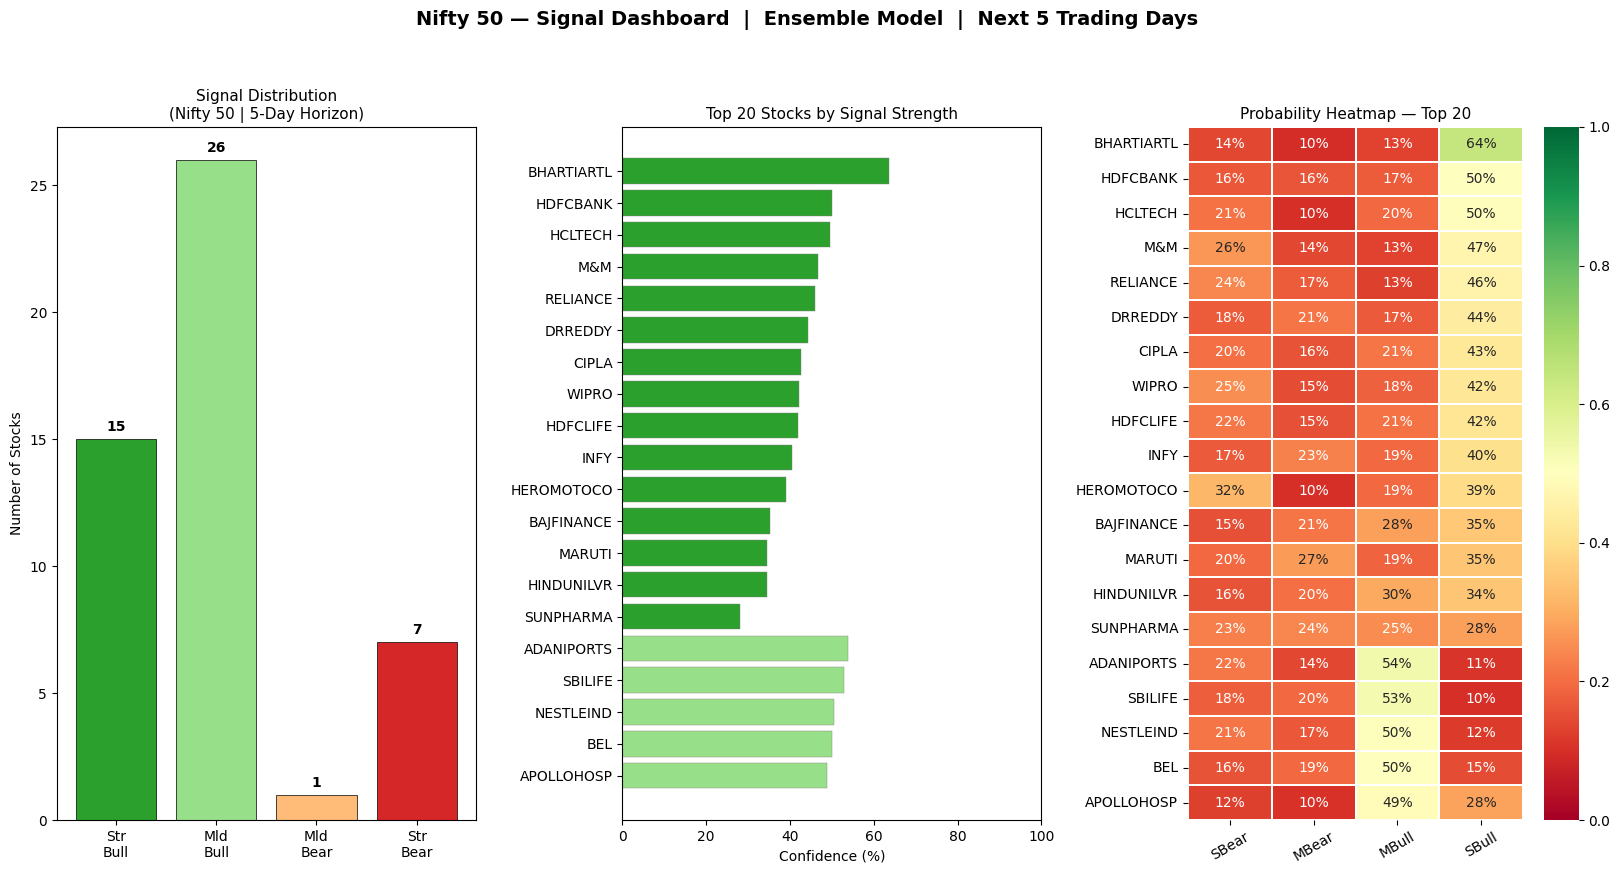

✅ Block 13 complete — nifty50_dashboard.png saved


In [15]:
# ============================================================
# BLOCK 13 — VISUAL SIGNAL DASHBOARD
# ============================================================

fig = plt.figure(figsize=(20, 9))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

colors_map = {
    'Strongly Bullish': '#2ca02c',
    'Mildly Bullish'  : '#98df8a',
    'Mildly Bearish'  : '#ffbb78',
    'Strongly Bearish': '#d62728',
}

# ── Panel 1: Signal distribution bar chart ───────────────
ax1 = fig.add_subplot(gs[0])
order  = ['Strongly Bullish','Mildly Bullish','Mildly Bearish','Strongly Bearish']
counts = results_df['Signal'].value_counts().reindex(order, fill_value=0)
bars   = ax1.bar(range(len(order)), counts.values,
                 color=[colors_map[s] for s in order],
                 edgecolor='black', linewidth=0.5)
ax1.set_xticks(range(len(order)))
ax1.set_xticklabels(['Str\nBull','Mld\nBull','Mld\nBear','Str\nBear'],
                    fontsize=10)
for bar, cnt in zip(bars, counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             str(cnt), ha='center', va='bottom', fontweight='bold')
ax1.set_ylabel("Number of Stocks")
ax1.set_title(f"Signal Distribution\n(Nifty 50 | {FORWARD_DAYS}-Day Horizon)",
              fontsize=11)

# ── Panel 2: Top 20 stocks by confidence ─────────────────
ax2 = fig.add_subplot(gs[1])
top20 = results_df.head(20)
bar_c = [colors_map[s] for s in top20['Signal']]
ax2.barh(top20['Ticker'], top20['Confidence'],
         color=bar_c, edgecolor='gray', linewidth=0.3)
ax2.set_xlabel("Confidence (%)")
ax2.set_title("Top 20 Stocks by Signal Strength", fontsize=11)
ax2.invert_yaxis()
ax2.set_xlim(0, 100)

# ── Panel 3: Probability heatmap ─────────────────────────
ax3 = fig.add_subplot(gs[2])
hm_cols = ['p_SBear','p_MBear','p_MBull','p_SBull']
hm_data = top20[hm_cols].values / 100.0
sns.heatmap(hm_data, annot=True, fmt='.0%', cmap='RdYlGn',
            yticklabels=top20['Ticker'].values,
            xticklabels=['SBear','MBear','MBull','SBull'],
            ax=ax3, linewidths=0.3, vmin=0, vmax=1)
ax3.set_title("Probability Heatmap — Top 20", fontsize=11)
ax3.tick_params(axis='x', rotation=30)

plt.suptitle(
    f"Nifty 50 — Signal Dashboard  |  Ensemble Model  |  "
    f"Next {FORWARD_DAYS} Trading Days",
    fontsize=14, fontweight='bold', y=1.01
)
plt.savefig("nifty50_dashboard.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Block 13 complete — nifty50_dashboard.png saved")